**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 5**
Preprocesamiento de datos

---


**Nombre:** Federico Castro Zenteno  
**Matrícula:** Pendiente de completar


En esta actividad trabajarás con el archivo `heart_disease.csv`, basado en un conjunto de datos sobre pacientes y variables clínicas relacionadas con enfermedades cardíacas, disponible en Kaggle.

Los datos fueron recopilados para analizar la presencia de enfermedades cardíacas en los pacientes y contienen información demográfica, clínica y resultados de pruebas diagnósticas. Los indicadores incluidos son:

* `id`: Identificador único de cada paciente
* `age`: Edad del paciente en años
* `origin`: Lugar de estudio
* `sex`: Masculino / Femenino
* `cp`: Tipo de dolor torácico (angina típica, angina atípica, no anginal, asintomático)
* `trestbps`: Presión arterial en reposo (en mm Hg al ingreso al hospital)
* `chol`: Colesterol sérico en mg/dl
* `fbs`: Si el azúcar en ayunas > 120 mg/dl
* `restecg`: Resultados del electrocardiograma en reposo (normal, anomalía ST-T, hipertrofia ventricular izquierda)
* `thalach`: Frecuencia cardíaca máxima alcanzada
* `exang`: Angina inducida por ejercicio (Verdadero / Falso)
* `oldpeak`: Depresión del segmento ST inducida por ejercicio respecto al reposo
* `slope`: Pendiente del segmento ST en el pico de ejercicio
* `ca`: Número de vasos principales coloreados por fluoroscopía (0 - 3)
* `thal`: Resultado de la prueba de perfusión cardíaca (normal, defecto fijo, defecto reversible)
* `num`: Indica si el paciente tiene o no enfermedad cardíaca, o el grado de enfermedad (0 = sano, 1 - 4 = enfermedad) Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.


El CSV y esta libreta deben estar en la misma carpeta. En Colab, subir `heart_disease.csv` al entorno antes de usar **Ejecutar todo**. Se conserva el nombre real `thalch` del archivo (la descripción también utiliza `thalach`).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind, chi2_contingency
from sklearn.impute import SimpleImputer
from IPython.display import display

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)


1. Descarga el archivo: `heart_disease.csv` y guarda, en un dataframe (`cardio_df`), todos sus registros.
* Haz que la columna `id` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Determina la cantidad de valores únicos por columna.


In [2]:
cardio_df = pd.read_csv('heart_disease.csv', index_col='id')
assert cardio_df.index.is_unique
cardio_df.info()
numericas_iniciales = cardio_df.select_dtypes(include='number').columns.tolist()
texto_iniciales = cardio_df.select_dtypes(include='object').columns.tolist()
display(pd.Series({'Registros': len(cardio_df), 'Columnas numéricas': len(numericas_iniciales),
                   'Columnas de texto/object': len(texto_iniciales)}))
display(cardio_df.nunique().rename('Valores únicos (sin NaN)').to_frame())
display(cardio_df.head())


<class 'pandas.core.frame.DataFrame'>
Index: 918 entries, 1 to 920
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       918 non-null    int64  
 1   sex       918 non-null    object 
 2   origin    918 non-null    object 
 3   cp        918 non-null    object 
 4   trestbps  859 non-null    float64
 5   chol      888 non-null    float64
 6   fbs       829 non-null    object 
 7   restecg   918 non-null    object 
 8   thalch    863 non-null    float64
 9   exang     863 non-null    object 
 10  oldpeak   856 non-null    float64
 11  slope     610 non-null    object 
 12  ca        309 non-null    float64
 13  thal      434 non-null    object 
 14  num       918 non-null    int64  
dtypes: float64(5), int64(2), object(8)
memory usage: 147.0+ KB


Registros                   918
Columnas numéricas            7
Columnas de texto/object      8
dtype: int64

,Valores únicos (sin NaN)
age,50
sex,2
origin,4
cp,4
trestbps,60
chol,216
fbs,2
restecg,3
thalch,119
exang,2


,age,sex,origin,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
id,,,,,,,,,,,,,,,
1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


Se cargan **918 pacientes** con `id` como índice, y **15 columnas: 7 numéricas y 8 de texto/object**. `fbs` y `exang` contienen valores booleanos y faltantes, aunque la lectura inicial los representa como object. Los faltantes no se cuentan como un valor único.


2. Examina las variables numéricas que presentan pocos valores únicos, ya que esto puede indicar que en realidad se tratan de variables categóricas codificadas como números.
* Si existen casos de este tipo, conviértelas a categóricas. Antes de hacerlo, revisa sus descripciones para determinar si son ordinales o nominales y, si son ordinales, establece el orden correcto de las categorías.


In [3]:
pocas_numericas = [c for c in numericas_iniciales if cardio_df[c].nunique() <= 10]
display(cardio_df[pocas_numericas].nunique().to_frame('Valores únicos'))
cardio_df['num'] = pd.Categorical(cardio_df['num'], categories=[0, 1, 2, 3, 4], ordered=True)
cardio_df['ca'] = pd.Categorical(cardio_df['ca'], categories=[0, 1, 2, 3], ordered=True)
cardio_df['slope'] = pd.Categorical(cardio_df['slope'],
                                  categories=['upsloping', 'flat', 'downsloping'], ordered=True)
for c in ['sex', 'origin', 'cp', 'fbs', 'restecg', 'exang', 'thal']:
    cardio_df[c] = cardio_df[c].astype('category')
display(cardio_df.dtypes.to_frame('Tipo después de convertir'))


,Valores únicos
ca,4
num,5


,Tipo después de convertir
age,int64
sex,category
origin,category
cp,category
trestbps,float64
chol,float64
fbs,category
restecg,category
thalch,float64
exang,category


Las numéricas con pocos valores únicos son `ca` (4) y `num` (5). Se trata `ca` como ordinal **0 < 1 < 2 < 3** para representar niveles del conteo de vasos, aunque también puede analizarse como conteo discreto. `num` es el target ordinal **0 < 1 < 2 < 3 < 4**, siguiendo la descripción del curso. No se utiliza el target para imputar predictores.

También se convierten las columnas object en categóricas. `sex`, `origin`, `cp`, `fbs`, `restecg`, `exang` y `thal` son nominales: sus categorías no implican una escala numérica de gravedad. Para `slope` se define el orden de pendiente **upsloping → flat → downsloping**, de ascendente a descendente; no se interpreta como una escala universal de gravedad clínica. Permanecen 5 numéricas y 10 categóricas.


3. Obtén las estadísticas descriptivas de las variables, realizando el análisis por separado para las variables numéricas y las categóricas.
* Para las numéricas, incluye el sesgo y la curtosis.
* Para las categóricas, imprime además las tablas de frecuencia.


In [4]:
numericas = cardio_df.select_dtypes(include='number').columns.tolist()
categoricas = cardio_df.select_dtypes(include='category').columns.tolist()
estadisticas = cardio_df[numericas].describe().T
estadisticas['sesgo'] = cardio_df[numericas].skew()
estadisticas['curtosis_exceso'] = cardio_df[numericas].kurt()
display(estadisticas)
display(cardio_df[categoricas].describe().T)
for c in categoricas:
    frecuencias = cardio_df[c].value_counts(dropna=False, sort=False)
    display(pd.DataFrame({'Frecuencia': frecuencias,
                          'Porcentaje': frecuencias / len(cardio_df) * 100}).rename_axis(c))


,count,mean,std,min,25%,50%,75%,max,sesgo,curtosis_exceso
age,918.0,53.530501,9.412783,28.0,47.0,54.0,60.0,77.0,-0.193710,-0.382511
trestbps,859.0,132.294529,18.535875,80.0,120.0,130.0,140.0,200.0,0.630411,0.632992
chol,888.0,242.189189,53.424806,85.0,216.0,223.0,268.0,603.0,1.640672,6.573848
thalch,863.0,137.528389,25.950226,60.0,120.0,140.0,157.0,202.0,-0.209319,-0.483939
oldpeak,856.0,0.880607,1.091840,-2.6,0.0,0.5,1.5,6.2,1.037990,1.119834


,count,unique,top,freq
sex,918,2,Male,724
origin,918,4,Cleveland,304
cp,918,4,asymptomatic,495
fbs,829,2,False,691
restecg,918,3,normal,551
exang,863,2,False,526
slope,610,3,flat,345
ca,309,4,0,181
thal,434,3,normal,196
num,918,5,0,411


,Frecuencia,Porcentaje
sex,,
Female,194,21.132898
Male,724,78.867102


,Frecuencia,Porcentaje
origin,,
Cleveland,304,33.115468
Hungary,292,31.808279
Switzerland,122,13.289760
VA Long Beach,200,21.786492


,Frecuencia,Porcentaje
cp,,
asymptomatic,495,53.921569
atypical angina,174,18.954248
non-anginal,204,22.222222
typical angina,45,4.901961


...

,Frecuencia,Porcentaje
exang,,
False,526,57.298475
True,337,36.710240
NaN,55,5.991285


,Frecuencia,Porcentaje
slope,,
upsloping,202,22.004357
flat,345,37.581699
downsloping,63,6.862745
NaN,308,33.551198


,Frecuencia,Porcentaje
ca,,
0,181,19.716776
1,67,7.298475
2,41,4.466231
3,20,2.178649
NaN,609,66.339869


,Frecuencia,Porcentaje
thal,,
fixed defect,46,5.010893
normal,196,21.350763
reversable defect,192,20.915033
NaN,484,52.723312


,Frecuencia,Porcentaje
num,,
0,411,44.771242
1,263,28.649237
2,109,11.873638
3,107,11.655773
4,28,3.050109


La curtosis reportada es de **exceso**: la referencia normal es 0. El sesgo describe la asimetría; las tablas categóricas incluyen faltantes para mostrar su peso en los 918 registros. La imputación con mediana se justifica por la asimetría y/o las observaciones extremas de las variables clínicas, visibles en las estadísticas y boxplots.


4. Calcula el porcentaje de valores faltantes en cada columna.
* Elimina aquellas columnas cuyo porcentaje de valores faltantes supere el 30%.
* Crea un mapa de calor que visualice la distribución de los valores faltantes en todas las columnas restantes.
* Algunas variables presentan valores faltantes de manera simultánea; es decir, en el mapa se pueden identificar filas donde varias están ausentes al mismo tiempo. Enumera cuáles son dichas variables e investiga si esta concurrencia tiene sentido desde un punto de vista médico o clínico.


,Faltantes (%)
age,0.000000
sex,0.000000
origin,0.000000
cp,0.000000
trestbps,6.427015
chol,3.267974
fbs,9.694989
restecg,0.000000
thalch,5.991285
exang,5.991285


0    slope
1       ca
2     thal
Name: Columnas eliminadas (>30%), dtype: object

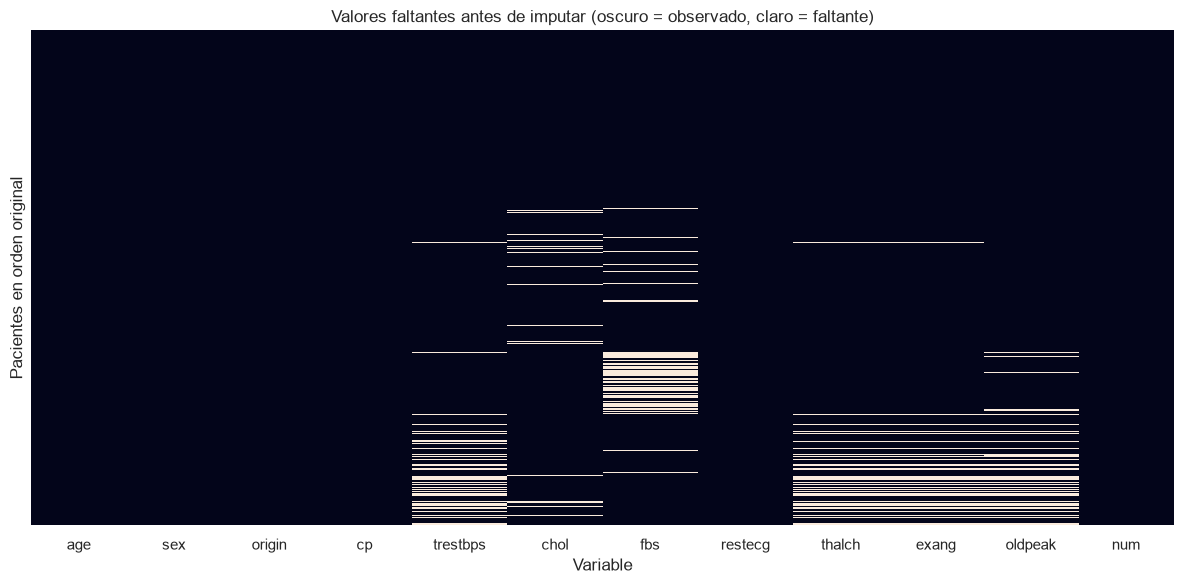

,Faltantes,Faltan junto con thalch,Jaccard
Variable,,,
trestbps,59,55,0.932203
exang,55,55,1.000000
oldpeak,62,54,0.857143


In [5]:
porcentaje_faltantes = cardio_df.isna().mean().mul(100)
display(porcentaje_faltantes.to_frame('Faltantes (%)'))
columnas_eliminadas = porcentaje_faltantes[porcentaje_faltantes > 30].index.tolist()
cardio_df = cardio_df.drop(columns=columnas_eliminadas)
display(pd.Series(columnas_eliminadas, name='Columnas eliminadas (>30%)'))

plt.figure(figsize=(12, 6))
sns.heatmap(cardio_df.isna(), cbar=False, yticklabels=False)
plt.title('Valores faltantes antes de imputar (oscuro = observado, claro = faltante)')
plt.xlabel('Variable')
plt.ylabel('Pacientes en orden original')
plt.tight_layout()
plt.show()

faltantes = cardio_df.isna()
comparacion = []
for c in ['trestbps', 'exang', 'oldpeak']:
    ambos = (faltantes['thalch'] & faltantes[c]).sum()
    union = (faltantes['thalch'] | faltantes[c]).sum()
    comparacion.append({'Variable': c, 'Faltantes': int(faltantes[c].sum()),
                        'Faltan junto con thalch': int(ambos), 'Jaccard': ambos / union})
display(pd.DataFrame(comparacion).set_index('Variable'))
variables_patron = ['thalch', 'exang', 'trestbps', 'oldpeak']


Se eliminan `slope` (**33.55%**), `ca` (**66.34%**) y `thal` (**52.72%**), por superar el 30%. Entre las columnas restantes, el patrón principal comprende **`thalch`, `exang`, `trestbps` y `oldpeak`**. Los 55 faltantes de `thalch` coinciden exactamente con los 55 de `exang`; también coinciden con 55 de los 59 faltantes de `trestbps` y 54 de los 62 de `oldpeak`.

Desde el contexto clínico, `thalch`, `exang` y `oldpeak` se obtienen en relación con la prueba de esfuerzo. Es plausible que la ausencia de esa prueba o de su registro afecte a varias mediciones a la vez. `trestbps` se mide en reposo: su concurrencia podría reflejar un registro incompleto del protocolo o del centro, pero no es una consecuencia necesaria de no realizar la prueba de esfuerzo. Es una explicación plausible, **no una causa demostrada** por este archivo. Fuente de las definiciones: [UCI, Heart Disease](https://archive.ics.uci.edu/dataset/45/heart+disease).


5. Si centramos el análisis en una de las variables identificadas en el ejercicio anterior, se puede suponer que los hallazgos obtenidos podrían ser aplicables a las demás variables que presentan un patrón similar.

* ¿Tendrán los valores faltantes de `thalch` relación con alguna otra variable? Analízalo considerando las siguientes columnas:
  *   Numéricas: `age`, `chol`
  *   Categóricas: `restecg`, `cp`

Para ello deberás dividir cada columna en dos grupos: con / sin faltantes en `thalch` y utilizar métodos gráficos y pruebas de hipótesis para ver si hay diferencias significativas.
* Incluye las conclusiones del análisis con los resultados obtenidos.
* Justifica si el mecanismo de faltantes de `thalch` es MCAR (*Missing Completely at Random*) o MAR (*Missing at Random*).

**NOTA**. Puedes reutilizar las funciones `Diagnose_MV_Numerical` y `Diagnose_MV_Categorical` definidas en Hands-On-Prep_Missing_Values.zip. Revisa nuevamente cómo utilizarlas.


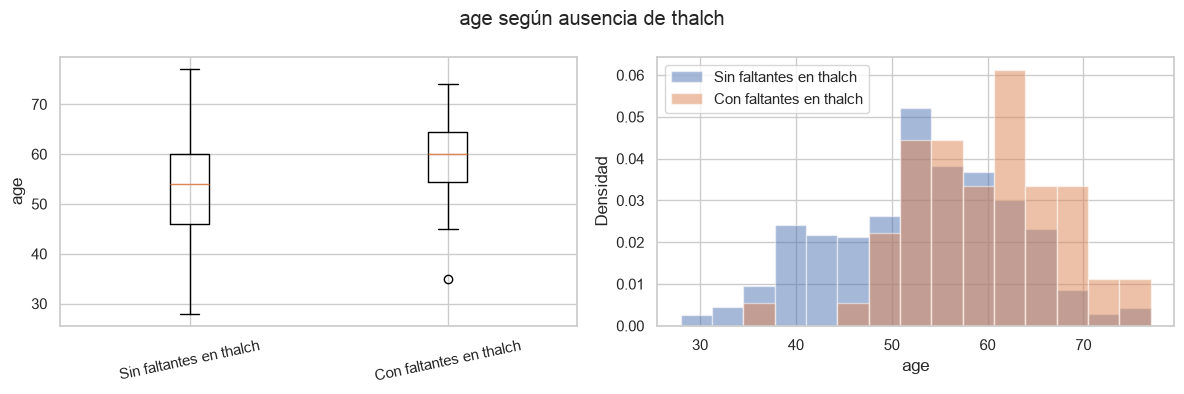

,n,Media,Mediana
Grupo,,,
Sin faltantes en thalch,863,53.155272,54.0
Con faltantes en thalch,55,59.418182,60.0


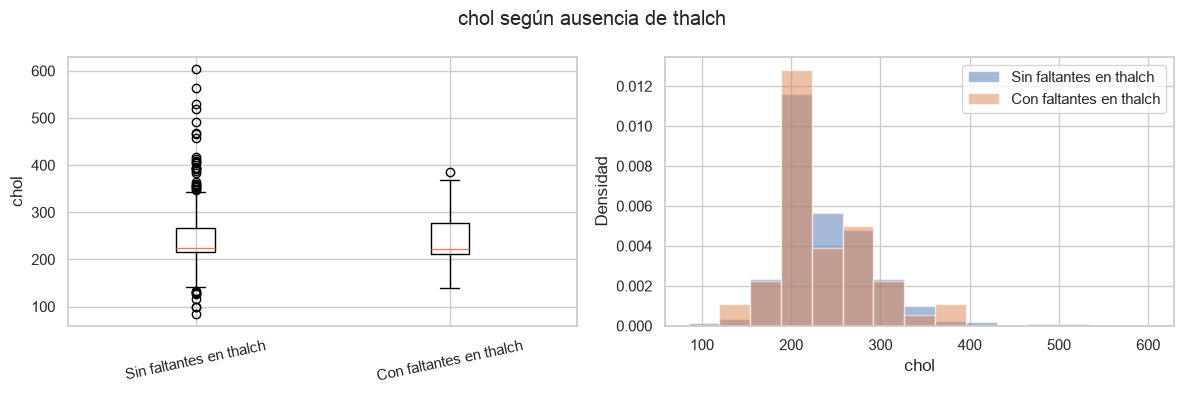

,n,Media,Mediana
Grupo,,,
Sin faltantes en thalch,836,242.351675,224.0
Con faltantes en thalch,52,239.576923,223.0


restecg,lv hypertrophy,normal,st-t abnormality
thalch,,,
Sin faltantes en thalch,181,532,150
Con faltantes en thalch,7,19,29


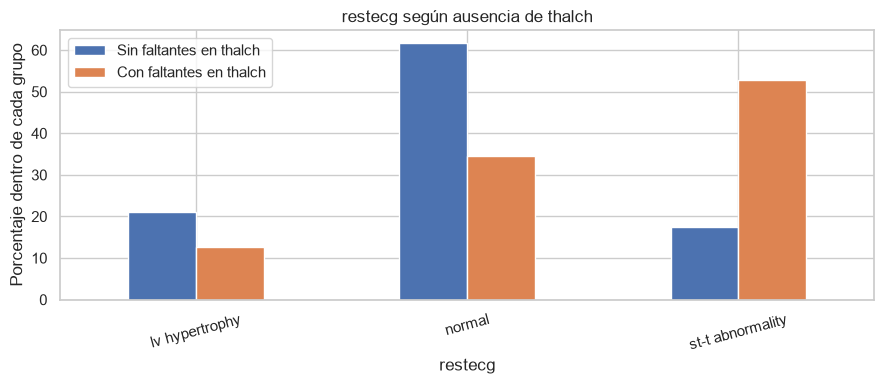

cp,asymptomatic,atypical angina,non-anginal,typical angina
thalch,,,,
Sin faltantes en thalch,469,167,186,41
Con faltantes en thalch,26,7,18,4


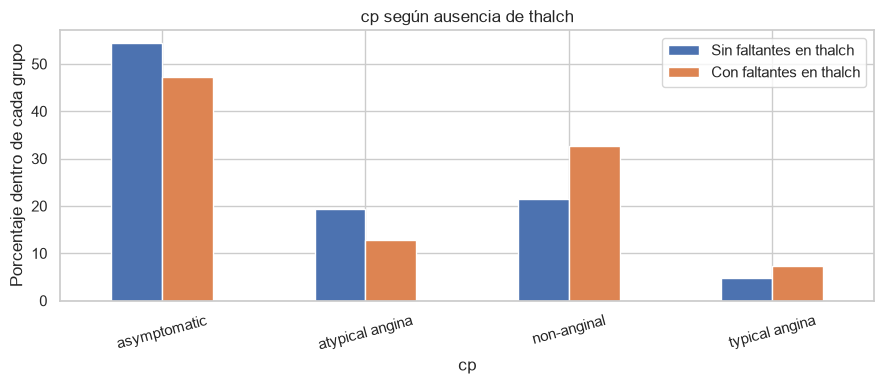

,Prueba,p,Media sin faltantes,Media con faltantes,Frecuencia esperada mínima
Variable,,,,,
age,t de Welch,4.115876e-07,53.155272,59.418182,NaN
chol,t de Welch,7.104716e-01,242.351675,239.576923,NaN
restecg,Chi-cuadrado,1.147289e-09,NaN,NaN,10.724401
cp,Chi-cuadrado,1.542010e-01,NaN,NaN,2.696078


In [6]:
BM_MV = cardio_df['thalch'].isna()
labels = ['Sin faltantes en thalch', 'Con faltantes en thalch']
resultados = []
for c in ['age', 'chol']:
    grupos = [cardio_df.loc[~BM_MV, c].dropna(), cardio_df.loc[BM_MV, c].dropna()]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].boxplot(grupos)
    axes[0].set_xticks([1, 2], labels, rotation=12)
    axes[0].set_ylabel(c)
    bins = np.histogram_bin_edges(cardio_df[c].dropna(), bins=15)
    for grupo, label in zip(grupos, labels):
        axes[1].hist(grupo, bins=bins, density=True, alpha=0.5, label=label)
    axes[1].set_xlabel(c)
    axes[1].set_ylabel('Densidad')
    axes[1].legend()
    fig.suptitle(f'{c} según ausencia de thalch')
    plt.tight_layout()
    plt.show()
    prueba = ttest_ind(grupos[0], grupos[1], equal_var=False)
    resultados.append({'Variable': c, 'Prueba': 't de Welch', 'p': float(prueba.pvalue),
                        'Media sin faltantes': grupos[0].mean(),
                        'Media con faltantes': grupos[1].mean()})
    display(pd.DataFrame({'Grupo': labels, 'n': [len(g) for g in grupos],
                          'Media': [g.mean() for g in grupos],
                          'Mediana': [g.median() for g in grupos]}).set_index('Grupo'))

for c in ['restecg', 'cp']:
    tabla = pd.crosstab(BM_MV, cardio_df[c])
    prueba = chi2_contingency(tabla)
    display(tabla.rename(index={False: labels[0], True: labels[1]}))
    proporciones = tabla.div(tabla.sum(axis=1), axis=0).mul(100)
    proporciones.index = labels
    proporciones.T.plot.bar(figsize=(9, 4))
    plt.ylabel('Porcentaje dentro de cada grupo')
    plt.title(f'{c} según ausencia de thalch')
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()
    resultados.append({'Variable': c, 'Prueba': 'Chi-cuadrado', 'p': float(prueba.pvalue),
                        'Frecuencia esperada mínima': float(prueba.expected_freq.min())})
resultados_df = pd.DataFrame(resultados).set_index('Variable')
display(resultados_df)


**Resultados y conclusiones (α = 0.05).** Para las numéricas, H₀ establece igualdad de medias entre pacientes con y sin faltantes en `thalch`; se usa Welch para no suponer varianzas iguales. Para las categóricas, H₀ establece independencia entre la categoría y la ausencia de `thalch`.

| Variable | Prueba | p | Interpretación |
|---|---|---:|---|
| `age` | t de Welch | 4.116 × 10⁻⁷ | Se rechaza H₀; hay diferencia de medias. |
| `chol` | t de Welch | 0.7105 | No se rechaza H₀. |
| `restecg` | Chi-cuadrado | 1.147 × 10⁻⁹ | Se rechaza independencia. |
| `cp` | Chi-cuadrado | 0.1542 | No se rechaza independencia. |

La edad media es **59.42 años con faltantes frente a 53.16 sin faltantes**. El colesterol medio es **239.58 frente a 242.35 mg/dl**, respectivamente. Se excluyen solo los NaN de cada comparación: en colesterol hay 52 observaciones con faltantes en `thalch` y 836 sin ellos. Las barras muestran porcentajes por grupo, pues sus tamaños son muy distintos (55 y 863).

La distribución de `restecg` cambia: la categoría ST-T anormal representa **52.73%** del grupo con faltantes y **17.38%** del grupo sin ellos. La frecuencia esperada mínima de su prueba es 10.72. En `cp`, una de las ocho celdas tiene frecuencia esperada inferior a 5 (mínimo 2.70), por lo que su p es aproximado y debe interpretarse con cautela. No rechazar H₀ no demuestra ausencia de relación. Las cuatro comparaciones son exploratorias; incluso usando el umbral conservador de Bonferroni 0.05/4 = 0.0125, las asociaciones de edad y `restecg` siguen siendo significativas.

**Mecanismo de ausencia.** Los resultados aportan evidencia contra **MCAR**, porque la ausencia de `thalch` se asocia con variables observadas (`age` y `restecg`). Entre las dos opciones solicitadas, **MAR es una hipótesis de trabajo más razonable**: se podría explicar parte de la ausencia usando información observada. Sin embargo, las pruebas no demuestran MAR ni descartan MNAR; determinarlo requeriría conocer el proceso de recolección. La coincidencia de faltantes sugiere investigar juntas las variables del mismo patrón, pero no permite trasladar automáticamente a todas ellas estas conclusiones.


6. La imputación de una variable con valores faltantes puede realizarse por grupos o segmentos relevantes. Esto significa que, en lugar de utilizar una estadística global de toda la columna, se calcula la estadística correspondiente dentro de cada grupo definido por otra variable, haciendo:

> `df['var_with_missing'] = df.groupby('related_var')['var_with_missing'].transform(lambda x: x.fillna(x.median()))`

* Utiliza la variable `restecg` para separar los grupos e imputar `thalch` y todas las variables con patrón de faltantes similar (identificadas en el ejercicio 4) Asegúrate de cambiar la función de agregado si hay variables no numéricas.
* Vuelve a generar el mapa de calor para verificar que los valores faltantes en estas variables hayan sido imputados.


,Antes,Después
thalch,55,0
exang,55,0
trestbps,59,0
oldpeak,62,0


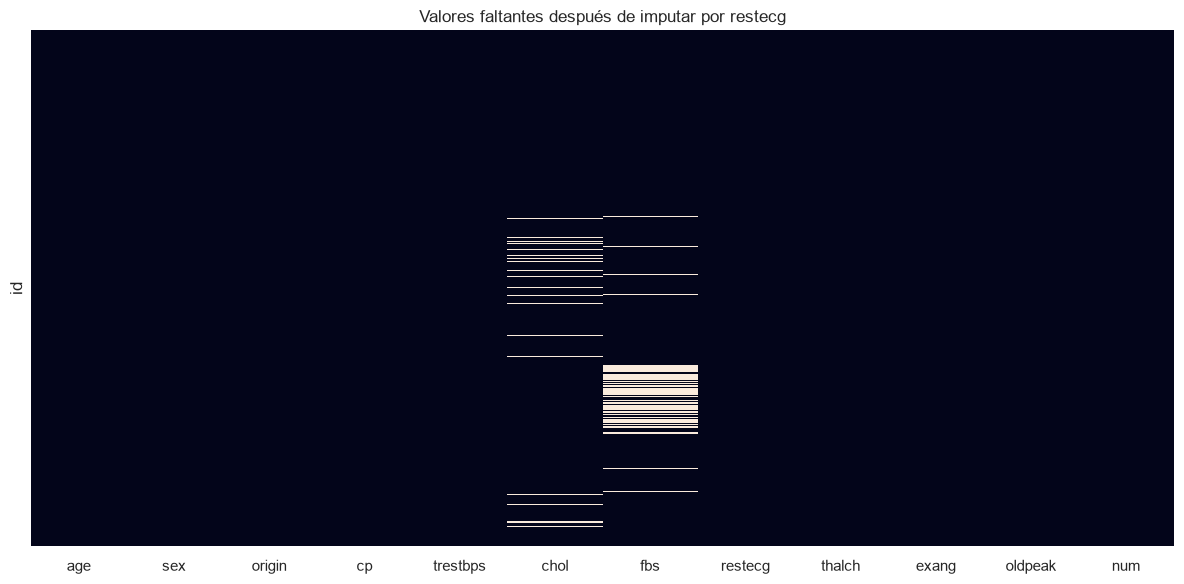

In [7]:
faltantes_antes_grupos = cardio_df[variables_patron].isna().sum()
for c in variables_patron:
    if pd.api.types.is_numeric_dtype(cardio_df[c]):
        cardio_df[c] = cardio_df.groupby('restecg', observed=True)[c].transform(
            lambda x: x.fillna(x.median()))
    else:
        cardio_df[c] = cardio_df.groupby('restecg', observed=True)[c].transform(
            lambda x: x.fillna(x.mode().iloc[0]) if not x.mode().empty else x)
        cardio_df[c] = cardio_df[c].astype('category')
display(pd.DataFrame({'Antes': faltantes_antes_grupos,
                      'Después': cardio_df[variables_patron].isna().sum()}))
assert not cardio_df[variables_patron].isna().any().any()
plt.figure(figsize=(12, 6))
sns.heatmap(cardio_df.isna(), cbar=False, yticklabels=False)
plt.title('Valores faltantes después de imputar por restecg')
plt.tight_layout()
plt.show()


Se usa la **mediana por `restecg`** para `thalch`, `trestbps` y `oldpeak`, y la **moda por `restecg`** para `exang`, que es nominal binaria. Todos los grupos tienen observaciones suficientes para obtener estos agregados y no quedan faltantes en las cuatro variables. La asociación observada con `restecg` motiva esta segmentación, aunque no demuestra que sea la mejor imputación para todas las variables; se sigue la estrategia solicitada.


7. Para las variables que aún presentan valores faltantes, realiza la imputación utilizando estadísticas generales calculadas sobre toda la columna, sin segmentar por grupos. Esta vez utiliza la clase `SimpleImputer` de sklearn
* Justifica la estrategia (*mean, median, most_frequent*) que emplees en cada caso.


In [8]:
estrategias_globales = {'chol': 'median', 'fbs': 'most_frequent'}
for c, estrategia in estrategias_globales.items():
    if cardio_df[c].isna().any():
        tipo_original = cardio_df[c].dtype
        entrada = cardio_df[[c]].copy()
        if isinstance(tipo_original, pd.CategoricalDtype):
            entrada[c] = entrada[c].astype(object)
            entrada[c] = entrada[c].where(entrada[c].notna(), np.nan)
        imputador = SimpleImputer(strategy=estrategia)
        cardio_df[c] = imputador.fit_transform(entrada).ravel()
        if isinstance(tipo_original, pd.CategoricalDtype):
            cardio_df[c] = cardio_df[c].astype(tipo_original)
display(cardio_df.isna().sum().to_frame('Faltantes después de imputar'))
assert not cardio_df.isna().any().any()


,Faltantes después de imputar
age,0
sex,0
origin,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalch,0
exang,0


Después de la imputación por grupos solamente quedan faltantes en `chol` (30) y `fbs` (89). Se emplea **median** para `chol` por la asimetría y valores extremos, y **most_frequent** para `fbs` por ser nominal binaria: promediarla produciría valores ajenos a sus categorías. Se mantienen los ceros originales de `chol` porque el ejercicio trata NaN como faltantes; su validez clínica merece revisión antes de modelar. La imputación es un ejercicio descriptivo; al entrenar un modelo, los agregados deben ajustarse solo con el conjunto de entrenamiento para evitar fuga de información.


8. Dibuja boxplots de todas las variables numéricas.
* Obtén los valores atípicos mediante el método gráfico, a partir del objeto devuelto por el boxplot.


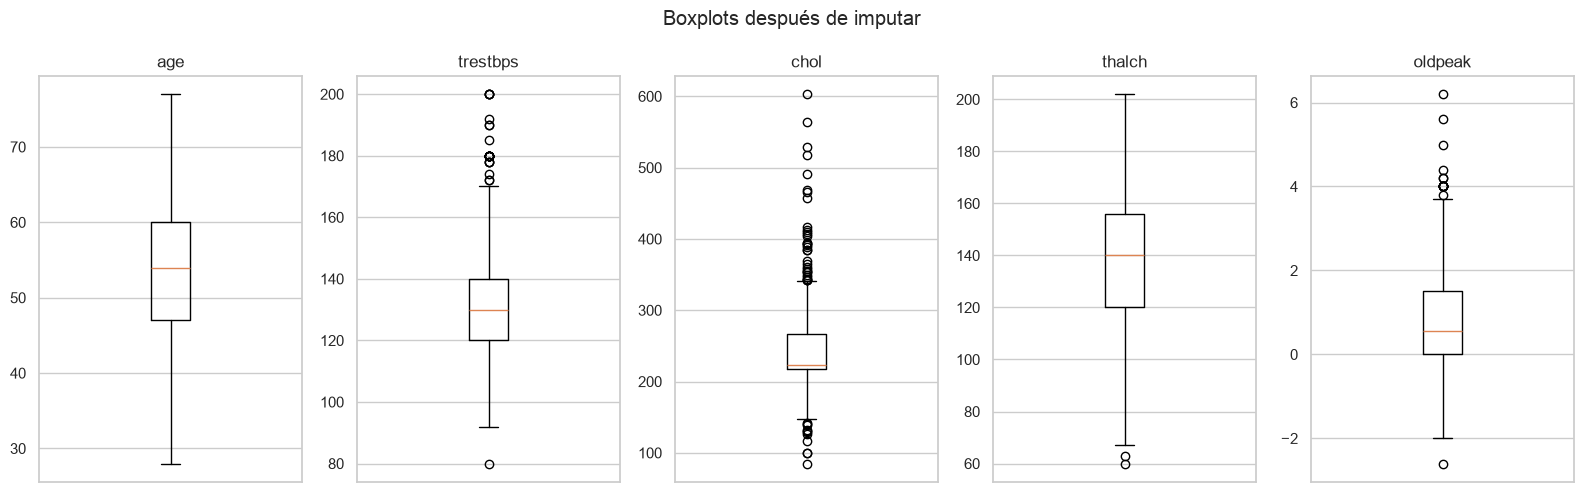

,Atípicos gráficos: age


,Atípicos gráficos: trestbps
0,80.0
1,172.0
2,180.0
3,200.0
4,174.0
5,178.0
6,192.0
7,180.0
8,178.0
9,180.0


,Atípicos gráficos: chol
0,141.0
1,126.0
2,131.0
3,132.0
4,129.0
5,100.0
6,85.0
7,117.0
8,100.0
9,142.0


,Atípicos gráficos: thalch
0,60.0
1,63.0


,Atípicos gráficos: oldpeak
0,-2.6
1,6.2
2,4.0
3,5.6
4,4.0
5,4.2
6,4.2
7,3.8
8,4.4
9,4.0


age          0
trestbps    27
chol        44
thalch       2
oldpeak     16
Name: Número de atípicos, dtype: int64

In [9]:
numericas = cardio_df.select_dtypes(include='number').columns.tolist()
fig, axes = plt.subplots(1, len(numericas), figsize=(16, 5))
atipicos_graficos = {}
for ax, c in zip(axes, numericas):
    objeto_boxplot = ax.boxplot(cardio_df[c].dropna(), whis=1.5)
    atipicos_graficos[c] = objeto_boxplot['fliers'][0].get_ydata().copy()
    ax.set_title(c)
    ax.set_xticks([])
plt.suptitle('Boxplots después de imputar')
plt.tight_layout()
plt.show()
for c, valores in atipicos_graficos.items():
    display(pd.Series(valores, name=f'Atípicos gráficos: {c}').to_frame())
display(pd.Series({c: len(v) for c, v in atipicos_graficos.items()}, name='Número de atípicos'))


Se obtienen los atípicos de las cinco variables numéricas directamente del elemento **`fliers`** del objeto devuelto por `boxplot`, conservando los valores repetidos. Son observaciones fuera de los bigotes de 1.5 IQR; esta clasificación estadística no prueba que una observación sea un error clínico.


9. Para la variable `trestbps`, calcula los valores atípicos utilizando el método del rango intercuartílico (IQR).
* Para ello obtén los cuartiles necesarios y determina los límites superior e inferior para filtrar los valores que se encuentren fuera de ese rango.
* Verifica si los resultados coinciden con los obtenidos en el ejercicio anterior.


In [10]:
q1 = cardio_df['trestbps'].quantile(0.25)
q3 = cardio_df['trestbps'].quantile(0.75)
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr
mascara_atipicos = (cardio_df['trestbps'] < limite_inferior) | (cardio_df['trestbps'] > limite_superior)
atipicos_iqr = cardio_df.loc[mascara_atipicos, 'trestbps']
coinciden = np.array_equal(np.sort(atipicos_iqr.to_numpy()),
                           np.sort(atipicos_graficos['trestbps']))
display(pd.Series({'Q1': q1, 'Q3': q3, 'IQR': iqr, 'Límite inferior': limite_inferior,
                   'Límite superior': limite_superior, 'Número de atípicos': len(atipicos_iqr),
                   'Coinciden con fliers': coinciden}))
display(atipicos_iqr.to_frame('trestbps atípico'))
assert coinciden


Q1                      120.0
Q3                      140.0
IQR                      20.0
Límite inferior          90.0
Límite superior         170.0
Número de atípicos         27
Coinciden con fliers     True
dtype: object

,trestbps atípico
id,
15,172.0
84,180.0
127,200.0
173,174.0
184,178.0
189,192.0
202,180.0
214,178.0
232,180.0


Para `trestbps`, **Q1 = 120**, **Q3 = 140** e **IQR = 20 mm Hg**. Los límites son **90 y 170 mm Hg**. Hay **27 registros** con valores menores a 90 o mayores a 170. La comparación de arreglos ordenados, incluidos valores repetidos, confirma que coinciden exactamente con los valores extraídos de `fliers`. Se usan los datos después de las imputaciones, en cumplimiento de la secuencia del ejercicio.


10. Elimina los valores atípicos identificados de la variable `trestbps`.
* Dibuja el boxplot final para visualizar la distribución depurada.


Registros antes         918
Registros eliminados     27
Registros finales       891
dtype: int64

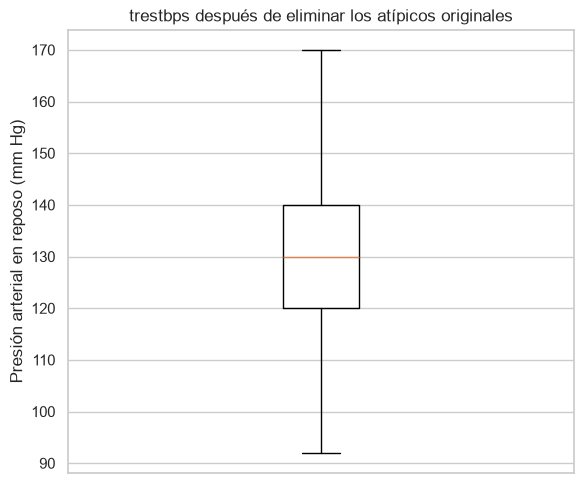

In [11]:
registros_antes = len(cardio_df)
cardio_df = cardio_df.loc[~mascara_atipicos].copy()
display(pd.Series({'Registros antes': registros_antes, 'Registros eliminados': int(mascara_atipicos.sum()),
                   'Registros finales': len(cardio_df)}))
plt.figure(figsize=(6, 5))
plt.boxplot(cardio_df['trestbps'], whis=1.5)
plt.title('trestbps después de eliminar los atípicos originales')
plt.ylabel('Presión arterial en reposo (mm Hg)')
plt.xticks([])
plt.tight_layout()
plt.show()
assert not cardio_df.isna().any().any()
assert cardio_df['trestbps'].between(limite_inferior, limite_superior).all()


Se eliminan los **27 registros** identificados en `trestbps`, pasando de **918 a 891 pacientes**. El dataframe final conserva **12 columnas y no contiene NaN**. Todas las presiones restantes están dentro de los límites originales [90, 170]. El boxplot final recalcula los cuartiles sobre los datos depurados; no se repite iterativamente la eliminación. Se cumple la depuración solicitada, aunque en una aplicación clínica se requeriría validar las observaciones antes de descartarlas.


**Declaración de uso de IA**

OpenAI. (2026). *Codex, basado en GPT-6* [Modelo de lenguaje grande], utilizado para generar código, apoyar el análisis estadístico, redactar explicaciones y depurar la libreta. https://openai.com/codex/

Esta solución fue elaborada con asistencia de IA. Federico Castro Zenteno debe revisar el contenido, comprender los procedimientos, completar su matrícula y asumir la responsabilidad de la versión que entregue.

**Referencia**

Janosi, A., Steinbrunn, W., Pfisterer, M. y Detrano, R. (1988). *Heart Disease*. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/45/heart+disease
